# LAB 11 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name: Nainsy chawla**
- **Roll No: 023-24-0261**
- **Section: H**
- **Date: 17-11-2026**

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

print("Slide 16:", predict([0.6, 0.8], [2, 3], -2))   # expected 1

w, b = [1, -0.5], 0.5
for x in ([1, 1], [2, 1], [0, 3]):
    print("Slide 17:", x, "->", predict(w, x, b))      # expected 1, 1, 0

Slide 16: 1
Slide 17: [1, 1] -> 1
Slide 17: [2, 1] -> 1
Slide 17: [0, 3] -> 0


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
data = [(0, 0, 0), (0, 1, 0), (1, 0, 0), (1, 1, 1)]
w = np.array([0.2, -0.1])
b = 0.0
eta = 0.1
mistakes = 0

for x1, x2, y in data:
    x = np.array([x1, x2])
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)
    e = y - y_hat
    if e != 0:
        mistakes += 1
    w = w + eta * e * x
    b = b + eta * e
    print(f"x={x}, y={y} | z={z:.2f}, y_hat={y_hat}, e={e} | w={np.round(w,2)}, b={b:.2f}")

print("\nFinal w:", np.round(w, 2), "b:", round(b, 2), "mistakes:", mistakes)
print("Converged!" if mistakes == 0 else "Keep training.")

x=[0 0], y=0 | z=0.00, y_hat=1, e=-1 | w=[ 0.2 -0.1], b=-0.10
x=[0 1], y=0 | z=-0.20, y_hat=0, e=0 | w=[ 0.2 -0.1], b=-0.10
x=[1 0], y=0 | z=0.10, y_hat=1, e=-1 | w=[ 0.1 -0.1], b=-0.20
x=[1 1], y=1 | z=-0.20, y_hat=0, e=1 | w=[0.2 0. ], b=-0.10

Final w: [0.2 0. ] b: -0.1 mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            y_hat = predict(w, xi, b)
            e = yi - y_hat
            if e != 0:
                w = w + eta * e * xi
                b = b + eta * e
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

X_or = np.array([[0,0],[0,1],[1,0],[1,1]])
y_or = np.array([0,1,1,1])
w_or, b_or, m_or = train_perceptron(X_or, y_or)
print("w =", w_or, "| b =", b_or)
print("mistakes per epoch:", m_or)

w = [0.1 0.1] | b = -0.1
mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

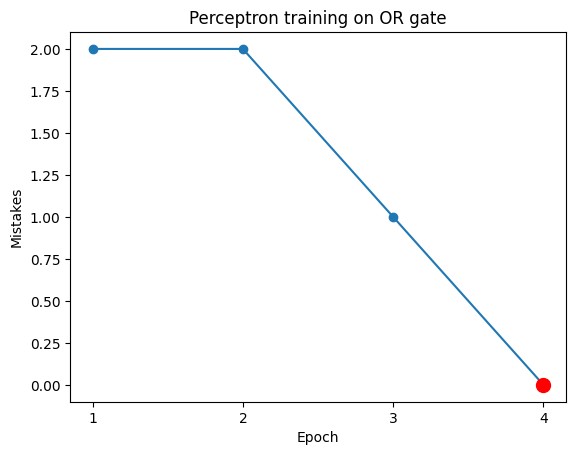

In [5]:
# Task 2.2
epochs = range(1, len(m_or) + 1)
plt.plot(epochs, m_or, marker='o')
plt.plot(len(m_or), m_or[-1], 'ro', markersize=10)   # final epoch
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch"); plt.ylabel("Mistakes")
plt.xticks(list(epochs))
plt.show()

**Interpretation:** *Mistakes fall from 2 → 2 → 1 → 0, so the perceptron converges in 4 epochs. The red dot marks the first error-free epoch, where training stops. This happens because OR is linearly separable, so convergence is guaranteed.*

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

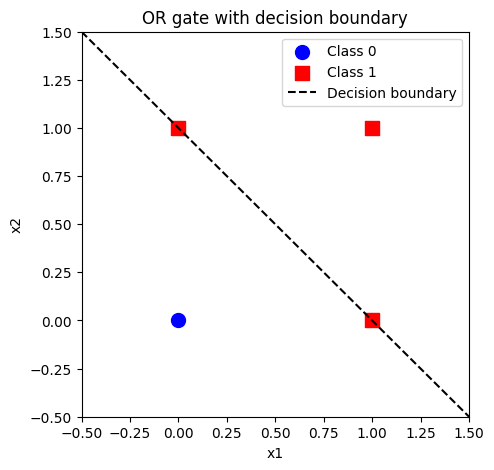

In [6]:
# Task 3.1
def plot_boundary(ax, w, b, xlim=(-0.5, 1.5), **kwargs):
    kwargs.setdefault('color', 'black')
    kwargs.setdefault('linestyle', '--')
    kwargs.setdefault('label', 'Decision boundary')
    if w[1] == 0:
        if w[0] != 0:
            ax.axvline(-b / w[0], **kwargs)        # vertical line
    else:
        x1 = np.linspace(xlim[0], xlim[1], 100)
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, **kwargs)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_or[y_or==0, 0], X_or[y_or==0, 1], c='blue', marker='o', s=100, label='Class 0')
ax.scatter(X_or[y_or==1, 0], X_or[y_or==1, 1], c='red', marker='s', s=100, label='Class 1')
plot_boundary(ax, w_or, b_or)
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_title("OR gate with decision boundary")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend()
plt.show()


**Interpretation:** *The learned boundary (w = [0.1, 0.1], b = −0.1) is the straight line x₂ = −x₁ + 1. ŷ = 1 on the upper-right side, the direction w points, including the line itself since z = 0 gives ŷ = 1. The class 1 points (0,1) and (1,0) lie on the line, (1,1) lies above it, and the class 0 point (0,0) lies below it.*

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias   : w = [0.1 0.1] b = -0.2 | epochs = 4 | final mistakes = 0
Without bias: w = [0.1 0. ] b = 0.0 | epochs = 100 | final mistakes = 2


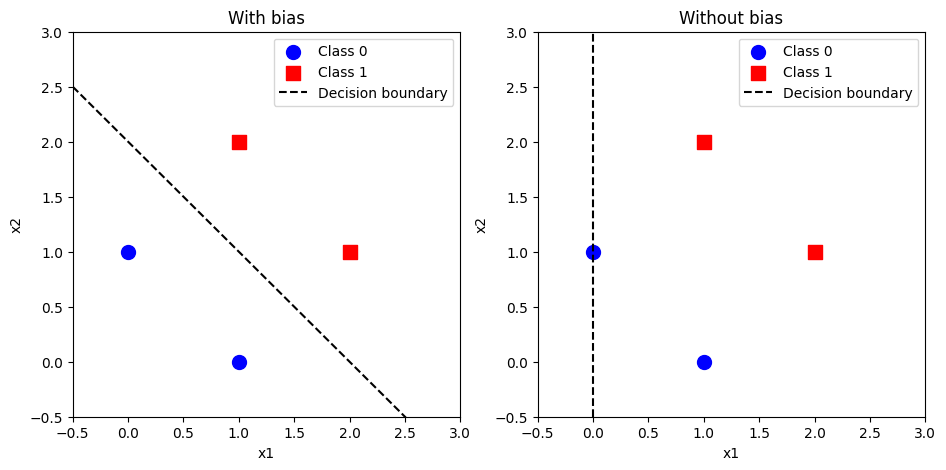

In [7]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    w = np.zeros(X.shape[1])
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, 0)
            if e != 0:
                w = w + eta * e * xi      # b stays 0
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, 0.0, mistakes

X32 = np.array([[1,0],[0,1],[2,1],[1,2]])
y32 = np.array([0,0,1,1])

w_b, b_b, m_b = train_perceptron(X32, y32)
w_nb, b_nb, m_nb = train_perceptron_nobias(X32, y32)
print("With bias   : w =", w_b, "b =", b_b, "| epochs =", len(m_b), "| final mistakes =", m_b[-1])
print("Without bias: w =", w_nb, "b =", b_nb, "| epochs =", len(m_nb), "| final mistakes =", m_nb[-1])

fig = plt.figure(figsize=(11, 5))
for k, (w_, b_, title) in enumerate([(w_b, b_b, "With bias"), (w_nb, b_nb, "Without bias")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(X32[y32==0, 0], X32[y32==0, 1], c='blue', marker='o', s=100, label='Class 0')
    ax.scatter(X32[y32==1, 0], X32[y32==1, 1], c='red', marker='s', s=100, label='Class 1')
    plot_boundary(ax, w_, b_, xlim=(-0.5, 3))
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend()
plt.show()

**Interpretation:** *With bias, the perceptron converged in 4 epochs with 0 mistakes and a boundary of x₁ + x₂ = 2 (w = [0.1, 0.1], b = −0.2). Without bias it did not converge: after 100 epochs it still made 2 mistakes, and its boundary is stuck as the vertical line x₁ = 0 through the origin. Removing the bias forces every boundary through the origin, so it cannot separate these points (slide 19).*

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Final mistakes: 4 | epochs run: 100
w = [-0.1  0. ] | b = 0.0


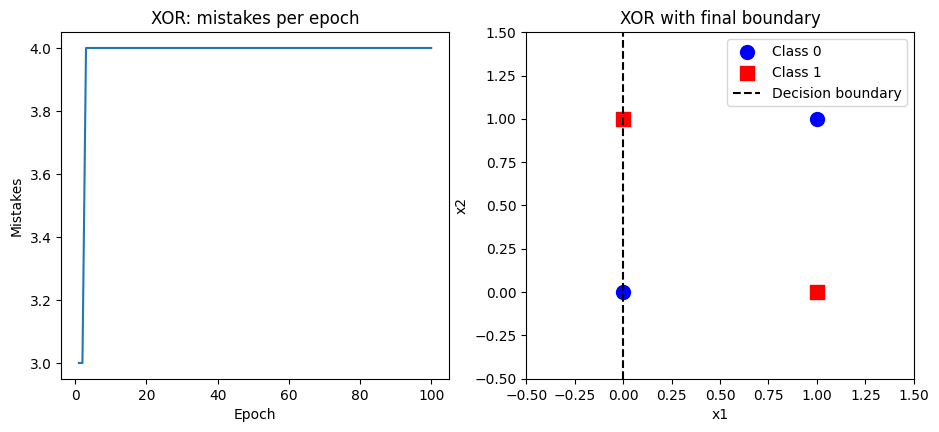

In [8]:
# Task 4.1
y_xor = np.array([0,1,1,0])
w_x, b_x, m_x = train_perceptron(X_or, y_xor, max_epochs=100)
print("Final mistakes:", m_x[-1], "| epochs run:", len(m_x))
print("w =", w_x, "| b =", b_x)

fig = plt.figure(figsize=(11, 4.5))
ax1 = plt.subplot(1, 2, 1)
ax1.plot(range(1, len(m_x)+1), m_x)
ax1.set_title("XOR: mistakes per epoch"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Mistakes")

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_or[y_xor==0, 0], X_or[y_xor==0, 1], c='blue', marker='o', s=100, label='Class 0')
ax2.scatter(X_or[y_xor==1, 0], X_or[y_xor==1, 1], c='red', marker='s', s=100, label='Class 1')
plot_boundary(ax2, w_x, b_x)
ax2.set_xlim(-0.5, 1.5); ax2.set_ylim(-0.5, 1.5)
ax2.set_title("XOR with final boundary"); ax2.set_xlabel("x1"); ax2.set_ylabel("x2"); ax2.legend()
plt.show()

**Interpretation:** *No, the perceptron never reaches zero mistakes: after all 100 epochs the last epoch still has 4 mistakes (w = [−0.1, 0], b = 0). XOR is not linearly separable, so every weight update that fixes one point breaks another, and the weights just cycle. A single straight line cannot separate the two diagonal pairs of points.*

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    return (np.dot(w, [0,0]) + b < 0 and
            np.dot(w, [0,1]) + b >= 0 and
            np.dot(w, [1,0]) + b >= 0 and
            np.dot(w, [1,1]) + b < 0)

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)

passed = [(W[i,0], W[i,1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]
print("Triples that pass:", len(passed), "out of 10000")
print("No solution found" if len(passed) == 0 else f"First passing triple: {passed[0]}")

Triples that pass: 0 out of 10000
No solution found


**Interpretation:** None of the 10,000 random (w₁, w₂, b) triples satisfied all four XOR constraints, which agrees with the algebraic proof in Q3(a) that no linear boundary exists.

## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X_iris = iris.data[:, (2, 3)]
y_iris = (iris.target == 0).astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris)

clf = Perceptron(random_state=42)
clf.fit(X_tr, y_tr)
y_pred = clf.predict(X_te)

print("Accuracy:", accuracy_score(y_te, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_te, y_pred))
print(classification_report(y_te, y_pred, target_names=["Rest", "Setosa"]))
print("coef_ :", clf.coef_)
print("intercept_ :", clf.intercept_)

Accuracy: 1.0
Confusion matrix:
 [[30  0]
 [ 0 15]]
              precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_ : [[-1.3 -2.2]]
intercept_ : [4.]


**Interpretation:** *All 45 test samples are classified correctly (accuracy = 1.0, confusion matrix has no off-diagonal entries, precision and recall are 1.0 for both classes). So Setosa is linearly separable from the other species on petal length and width. coef_ = [−1.3, −2.2] is the weight vector w (w₁, w₂) and intercept_ = 4.0 is the bias b from Part 1.*

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

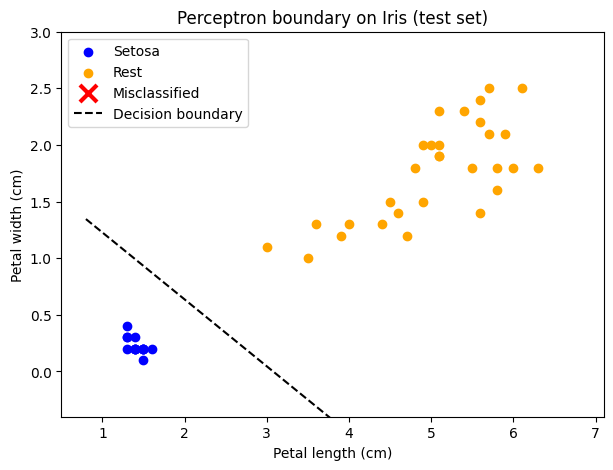

Misclassified test points: 0


In [11]:
# Task 5.2
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_te[y_te==1, 0], X_te[y_te==1, 1], c='blue', label='Setosa')
ax.scatter(X_te[y_te==0, 0], X_te[y_te==0, 1], c='orange', label='Rest')

wrong = y_pred != y_te
ax.scatter(X_te[wrong, 0], X_te[wrong, 1], c='red', marker='x', s=150, linewidths=3, label='Misclassified', zorder=5)

plot_boundary(ax, clf.coef_[0], clf.intercept_[0], xlim=(X_te[:,0].min()-0.5, X_te[:,0].max()+0.5))
ax.set_ylim(X_te[:,1].min()-0.5, X_te[:,1].max()+0.5)
ax.set_title("Perceptron boundary on Iris (test set)")
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)"); ax.legend()
plt.show()
print("Misclassified test points:", wrong.sum())

**Interpretation:** *0 of the 45 test points are misclassified (no red ×). The boundary −1.3x₁ − 2.2x₂ + 4 = 0 is a straight line, because z = 0 is linear in the two features. Setosa’s small petals fall on the ŷ = 1 side with a clear gap from the other two species.*

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
print(f"{'eta0':>8} | {'accuracy':>8} | {'n_iter_':>7} | coef_")
preds = {}
for eta0 in [0.001, 0.1, 10.0]:
    m = Perceptron(eta0=eta0, random_state=42).fit(X_tr, y_tr)
    p = m.predict(X_te)
    preds[eta0] = p
    print(f"{eta0:>8} | {accuracy_score(y_te, p):>8.4f} | {m.n_iter_:>7} | {m.coef_[0]} (intercept {m.intercept_[0]})")

print("Predictions identical across all eta0:",
      np.array_equal(preds[0.001], preds[0.1]) and np.array_equal(preds[0.1], preds[10.0]))

    eta0 | accuracy | n_iter_ | coef_
   0.001 |   1.0000 |       6 | [-0.0013 -0.0022] (intercept 0.004)
     0.1 |   1.0000 |       7 | [-0.13 -0.22] (intercept 0.4)
    10.0 |   1.0000 |       7 | [-13. -22.] (intercept 40.0)
Predictions identical across all eta0: True


**Interpretation:** *The predictions do not change: accuracy is 1.0 for all three η values and the predictions are identical. Starting from w = 0, the weights are just scaled: coef_ ≈ η × [−1.3, −2.2] and intercept_ ≈ η × 4, so η rescales w and b but never changes the sign of z, i.e. the boundary line. The tiny difference in n_iter_ (6 vs 7) comes from sklearn’s stopping rule.*

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X_all, y_all = iris.data, iris.target
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_all, y_all, test_size=0.3, random_state=42, stratify=y_all)

clf_p = Perceptron(random_state=42, max_iter=1000).fit(Xa_tr, ya_tr)
ya_pred_p = clf_p.predict(Xa_te)

print(classification_report(ya_te, ya_pred_p, target_names=iris.target_names, zero_division=0))
print("Confusion matrix:\n", confusion_matrix(ya_te, ya_pred_p))
print("coef_.shape:", clf_p.coef_.shape)

              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)


**Interpretation:** *Each row of coef_ (shape 3×4) is one one-vs-rest perceptron: one row per class, with one weight per feature. Versicolor is hardest (recall = 0.00): 14 of its 15 test flowers were predicted as setosa and 1 as virginica. It lies between the other two classes, so no single line separates it from both, and the overall accuracy is only 0.667.*

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
lr = LogisticRegression(random_state=42, max_iter=200).fit(Xa_tr, ya_tr)
ya_pred_lr = lr.predict(Xa_te)

print(f"{'Model':<20} | {'Accuracy':>8} | {'Macro-F1':>8}")
print(f"{'Perceptron':<20} | {accuracy_score(ya_te, ya_pred_p):>8.4f} | {f1_score(ya_te, ya_pred_p, average='macro'):>8.4f}")
print(f"{'Logistic Regression':<20} | {accuracy_score(ya_te, ya_pred_lr):>8.4f} | {f1_score(ya_te, ya_pred_lr, average='macro'):>8.4f}")

Model                | Accuracy | Macro-F1
Perceptron           |   0.6667 |   0.5499
Logistic Regression  |   0.9333 |   0.9333


**Interpretation:** *Logistic regression clearly beats the perceptron (accuracy and macro-F1 of 0.933 vs 0.667 and 0.550). Its sigmoid output is smooth with a never-zero gradient, so every sample (even already-correct ones) tells it how to adjust, whereas the step function only says “right” or “wrong”. The perceptron also keeps oscillating on classes that are not linearly separable, like versicolor*

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

*z = w·x + b = 0.5(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = **0.1**, so ŷ = step(0.1) = **1**.

The true label is y = 0, so e = y − ŷ = 0 − 1 = **−1** (a mistake, so we update).

- w₁ = 0.5 + 0.1(−1)(1) = **0.4**
- w₂ = −0.3 + 0.1(−1)(2) = **−0.5**
- b = 0.2 + 0.1(−1) = **0.1***

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

*The boundary is 0.3x₁ + 0.2x₂ − 0.4 = 0, i.e. x₂ = −1.5x₁ + 2.
At (1, 1): z = 0.3 + 0.2 − 0.4 = 0.1 ≥ 0, so (1,1) lies on the positive side of the line (above it, the side w points to) and ŷ = 1. This is correct for AND, since (1,1) is the only class-1 point.*

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**(a)** With z = w₁x₁ + w₂x₂ + b, the four XOR constraints are:

- (0,0) → 0: b < 0
- (0,1) → 1: w₂ + b ≥ 0
- (1,0) → 1: w₁ + b ≥ 0
- (1,1) → 0: w₁ + w₂ + b < 0

Adding the two ≥ 0 constraints gives w₁ + w₂ + 2b ≥ 0, so w₁ + w₂ ≥ −2b.
The fourth constraint gives w₁ + w₂ < −b.
Combining: −2b ≤ w₁ + w₂ < −b, which implies −2b < −b, so b > 0.
This contradicts b < 0 from the first constraint, so no (w₁, w₂, b) satisfies all four.

**(b)** The plot below shows the class 0 points (0,0) and (1,1) on one diagonal and the class 1 points (0,1) and (1,0) on the other. Any single straight line that separates one pair from the other must also cut through the remaining points, so XOR is not linearly separable.

**(c)** Add a hidden layer (a multi-layer perceptron). For example, XOR = AND(OR(x₁, x₂), NAND(x₁, x₂)), which two hidden units plus one output unit can compute.

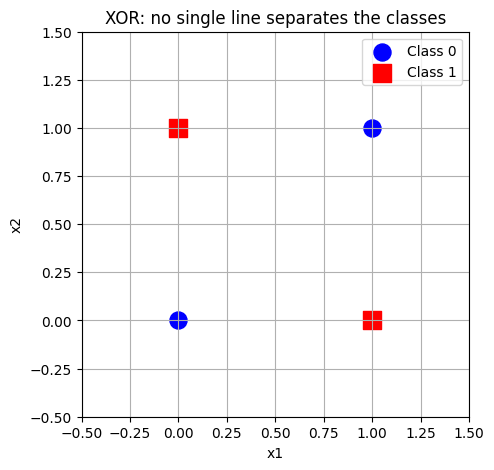

In [15]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_or[y_xor==0, 0], X_or[y_xor==0, 1], c='blue', marker='o', s=150, label='Class 0')
ax.scatter(X_or[y_xor==1, 0], X_or[y_xor==1, 1], c='red', marker='s', s=150, label='Class 1')
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_title("XOR: no single line separates the classes")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(True)
plt.show()

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [16]:
# Q4
X4 = iris.data[:, (0, 2, 3)]
X4_tr, X4_te, y4_tr, y4_te = train_test_split(X4, y_iris, test_size=0.3, random_state=42, stratify=y_iris)
clf4 = Perceptron(random_state=42).fit(X4_tr, y4_tr)
p4 = clf4.predict(X4_te)

print("Features (0,2,3): accuracy =", accuracy_score(y4_te, p4), "| macro-F1 =", f1_score(y4_te, p4, average='macro'))
print("Features (2,3)  : accuracy =", accuracy_score(y_te, y_pred), "| macro-F1 =", f1_score(y_te, y_pred, average='macro'))
print("coef_:", clf4.coef_, "| intercept_:", clf4.intercept_)

Features (0,2,3): accuracy = 1.0 | macro-F1 = 1.0
Features (2,3)  : accuracy = 1.0 | macro-F1 = 1.0
coef_: [[ 4.5 -8.7 -4.1]] | intercept_: [2.]


*Adding sepal length (features 0, 2, 3) gives accuracy = 1.0 and macro-F1 = 1.0. The original two-feature model (petal length and width) already scored accuracy = 1.0 and macro-F1 = 1.0. So the extra feature did not help: the numbers are identical, and there is no room to improve on a perfect score. Setosa is already linearly separable from the other species using petal length and width alone. The learned weights changed to coef_ = [4.5, −8.7, −4.1] with intercept_ = 2.0, which shows the model now uses sepal length, but the boundary is just a different plane that separates the same test points. The extra feature only adds complexity without any measurable gain here.*

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Hand-built: acc = 0.6333333333333333 | epochs = 1000 | w = [ 0.13546212 -0.06914304] | b = 0.20000000000000004
sklearn   : acc = 0.6666666666666666 | epochs = 6 | w = [2.28133191 0.57972588] | b = 2.0


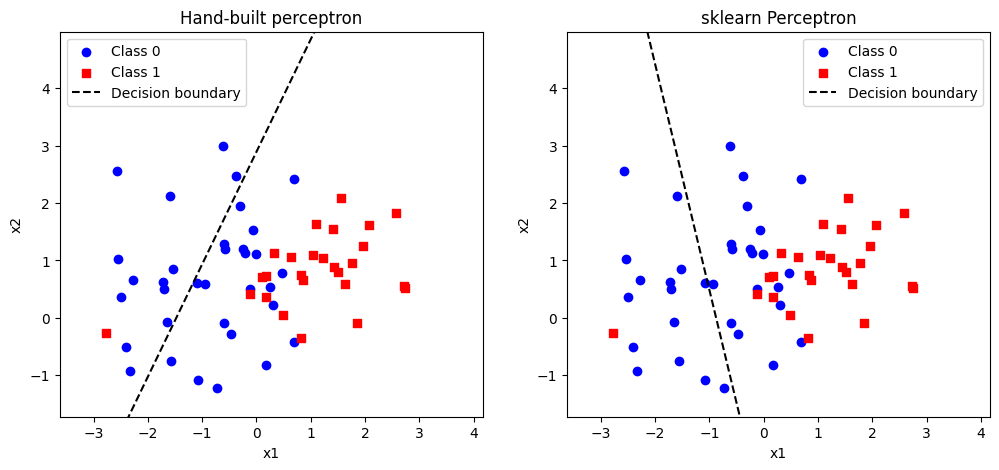

In [17]:
# Q5
Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=42)

# Hand-built
w_h, b_h, m_h = train_perceptron(Xs_tr, ys_tr, eta=0.1, max_epochs=1000)
pred_h = np.array([predict(w_h, xi, b_h) for xi in Xs_te])

# sklearn
clf_s = Perceptron(random_state=42).fit(Xs_tr, ys_tr)
pred_s = clf_s.predict(Xs_te)

print("Hand-built: acc =", accuracy_score(ys_te, pred_h), "| epochs =", len(m_h), "| w =", w_h, "| b =", b_h)
print("sklearn   : acc =", accuracy_score(ys_te, pred_s), "| epochs =", clf_s.n_iter_, "| w =", clf_s.coef_[0], "| b =", clf_s.intercept_[0])

xl = (Xs[:,0].min()-0.5, Xs[:,0].max()+0.5)
yl = (Xs[:,1].min()-0.5, Xs[:,1].max()+0.5)
fig = plt.figure(figsize=(12, 5))
for k, (w_, b_, title) in enumerate([(w_h, b_h, "Hand-built perceptron"),
                                      (clf_s.coef_[0], clf_s.intercept_[0], "sklearn Perceptron")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(Xs_te[ys_te==0, 0], Xs_te[ys_te==0, 1], c='blue', marker='o', label='Class 0')
    ax.scatter(Xs_te[ys_te==1, 0], Xs_te[ys_te==1, 1], c='red', marker='s', label='Class 1')
    plot_boundary(ax, w_, b_, xlim=xl)
    ax.set_xlim(xl); ax.set_ylim(yl)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend()
plt.show()

*Both perceptrons reach only about 63 to 67% test accuracy, and the hand-built one used all 1000 epochs without ever reaching a zero-mistake epoch. This means the synthetic data is not linearly separable (the two classes overlap), so the perceptron learning rule keeps updating and never converges. The two models ended with different weights and boundaries because they use different training procedures. My hand-built version has a fixed η = 0.1, no shuffling and no tolerance-based stopping, so its last weights are just wherever epoch 1000 happened to stop. The sklearn version stops early after about 6 epochs using its tolerance-based rule, and it shuffles the data. The slightly higher accuracy of sklearn (0.667 vs 0.633) is a small difference on 60 test points, which is only about 2 samples, so neither model is clearly better. Both boundaries are straight lines (see plots) and both misclassify points from the overlapping region. This shows the perceptron’s limit on non-separable data, where a model with a smooth loss, such as logistic regression, would do better.
The plots show that the two boundaries have clearly different orientations: the hand-built line tilts upward (positive slope) and the sklearn line is almost vertical. Both are straight lines, and both misclassify points in the central region where the blue and red classes overlap, so neither can reach perfect accuracy. The final boundary of a perceptron on non-separable data depends on where training happens to stop.*